# Session 9 · Pattern Mining and Visualization with Seaborn

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-09-pattern-mining-and-seaborn.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: Apriori from scratch

In [1]:
"""A small, readable Apriori implementation: join, prune, count, and rule generation."""
from itertools import combinations

baskets = [{"tea", "sugar", "rusk"}, {"tea", "sugar"}, {"tea", "milk", "rusk"}, {"bread", "eggs", "milk"},
           {"bread", "eggs"}, {"tea", "sugar", "milk"}, {"bread", "milk", "eggs", "tea"}, {"tea", "rusk"},
           {"sugar", "tea", "rusk"}, {"eggs", "bread", "butter"}]
N, MIN_SUP, MIN_CONF = len(baskets), 0.3, 0.6

def support(itemset):
    return sum(itemset <= b for b in baskets) / N          # <= means 'is a subset of'

items = sorted({i for b in baskets for i in b})
L = [{frozenset([i]) for i in items if support({i}) >= MIN_SUP}]
print("L1:", sorted("".join(sorted(s)) for s in L[0]))
k = 2
while L[-1]:
    prev = L[-1]
    candidates = {a | b for a in prev for b in prev if len(a | b) == k}                         # join
    candidates = {c for c in candidates if all(frozenset(s) in prev for s in combinations(c, k - 1))}  # prune
    Lk = {c for c in candidates if support(c) >= MIN_SUP}                                       # count
    print(f"C{k}: {len(candidates)} candidates -> L{k}: {[sorted(c) for c in Lk]}")
    L.append(Lk); k += 1

print("\nRules (confidence >= 0.6):")
for level in L[1:]:
    for itemset in level:
        for r in range(1, len(itemset)):
            for A in map(frozenset, combinations(itemset, r)):
                B = itemset - A
                conf = support(itemset) / support(A)
                if conf >= MIN_CONF:
                    lift = conf / support(B)
                    print(f"  {sorted(A)} -> {sorted(B)}  support={support(itemset):.2f}  confidence={conf:.2f}  lift={lift:.2f}")

L1: ['bread', 'eggs', 'milk', 'rusk', 'sugar', 'tea']
C2: 15 candidates -> L2: [['milk', 'tea'], ['bread', 'eggs'], ['rusk', 'tea'], ['sugar', 'tea']]
C3: 0 candidates -> L3: []

Rules (confidence >= 0.6):
  ['milk'] -> ['tea']  support=0.30  confidence=0.75  lift=1.07
  ['eggs'] -> ['bread']  support=0.40  confidence=1.00  lift=2.50
  ['bread'] -> ['eggs']  support=0.40  confidence=1.00  lift=2.50
  ['rusk'] -> ['tea']  support=0.40  confidence=1.00  lift=1.43
  ['sugar'] -> ['tea']  support=0.40  confidence=1.00  lift=1.43


### Example 2 · Intermediate: Eclat with tid-lists

In [2]:
"""Eclat: vertical tid-lists and depth-first intersection to find frequent itemsets."""
baskets = [{"tea", "sugar", "rusk"}, {"tea", "sugar"}, {"tea", "milk", "rusk"}, {"bread", "eggs", "milk"},
           {"bread", "eggs"}, {"tea", "sugar", "milk"}, {"bread", "milk", "eggs", "tea"}, {"tea", "rusk"},
           {"sugar", "tea", "rusk"}, {"eggs", "bread", "butter"}]
MIN_COUNT = 3                                      # = support 0.3 with 10 transactions

tid = {}
for t, b in enumerate(baskets, 1):
    for item in b:
        tid.setdefault(item, set()).add(t)
print("vertical format (tid-lists):")
for item in sorted(tid):
    print(f"  {item:<7} {sorted(tid[item])}")

results = []
def eclat(prefix, candidates):
    """candidates: list of (item, tidset) that can extend prefix, sorted."""
    for i, (item, tids) in enumerate(candidates):
        if len(tids) < MIN_COUNT:
            continue
        itemset = prefix + [item]
        results.append((itemset, len(tids)))
        # extend with later items by intersecting tid-lists
        ext = [(other, tids & otids) for other, otids in candidates[i + 1:]]
        eclat(itemset, ext)

eclat([], sorted(tid.items()))
print("\nfrequent itemsets (count >= 3):")
for itemset, c in sorted(results, key=lambda r: (len(r[0]), -r[1])):
    print(f"  {', '.join(itemset):<22} count={c}  support={c / len(baskets):.1f}")

vertical format (tid-lists):
  bread   [4, 5, 7, 10]
  butter  [10]
  eggs    [4, 5, 7, 10]
  milk    [3, 4, 6, 7]
  rusk    [1, 3, 8, 9]
  sugar   [1, 2, 6, 9]
  tea     [1, 2, 3, 6, 7, 8, 9]

frequent itemsets (count >= 3):
  tea                    count=7  support=0.7
  bread                  count=4  support=0.4
  eggs                   count=4  support=0.4
  milk                   count=4  support=0.4
  rusk                   count=4  support=0.4
  sugar                  count=4  support=0.4
  bread, eggs            count=4  support=0.4
  rusk, tea              count=4  support=0.4
  sugar, tea             count=4  support=0.4
  milk, tea              count=3  support=0.3


### Example 3 · Intermediate: building an FP-Tree and mining with FP-Growth

In [3]:
"""Build an FP-Tree by hand to see its structure, then mine with mlxtend's fpgrowth and compare with apriori."""
import time
from collections import Counter
import numpy as np
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

baskets = [["tea", "sugar", "rusk"], ["tea", "sugar"], ["tea", "milk", "rusk"], ["bread", "eggs", "milk"],
           ["bread", "eggs"], ["tea", "sugar", "milk"], ["bread", "milk", "eggs", "tea"], ["tea", "rusk"],
           ["sugar", "tea", "rusk"], ["eggs", "bread", "butter"]]
MIN_COUNT = 3
freq = Counter(i for b in baskets for i in b)
order = {i: c for i, c in freq.items() if c >= MIN_COUNT}
print("item order by frequency:", sorted(order.items(), key=lambda x: -x[1]))

class Node:
    def __init__(self, item, parent):
        self.item, self.parent, self.count, self.children = item, parent, 0, {}

root = Node(None, None)
for b in baskets:
    path = sorted([i for i in b if i in order], key=lambda i: (-order[i], i))   # sort by frequency
    node = root
    for item in path:
        node = node.children.setdefault(item, Node(item, node))
        node.count += 1

def show(node, depth=0):
    for child in sorted(node.children.values(), key=lambda n: -n.count):
        print("  " * depth + f"{child.item}:{child.count}")
        show(child, depth + 1)
print("\nFP-Tree:"); show(root)

# mlxtend on a bigger synthetic data set: apriori vs fpgrowth speed
rng = np.random.default_rng(0)
items = [f"item{i:02d}" for i in range(40)]
pop = rng.dirichlet(np.ones(40) * .4)
big = [list(rng.choice(items, size=rng.integers(2, 12), replace=False, p=pop)) for _ in range(5000)]
te = TransactionEncoder(); onehot = pd.DataFrame(te.fit(big).transform(big), columns=te.columns_)
for name, fn in [("apriori", apriori), ("fpgrowth", fpgrowth)]:
    t0 = time.perf_counter(); res = fn(onehot, min_support=0.02, use_colnames=True); dt = time.perf_counter() - t0
    print(f"{name:<9} {len(res):>5} frequent itemsets in {dt:.2f} s")

item order by frequency: [('tea', 7), ('sugar', 4), ('rusk', 4), ('milk', 4), ('bread', 4), ('eggs', 4)]

FP-Tree:
tea:7
  rusk:3
    sugar:2
  milk:2
    rusk:1
    sugar:1
  sugar:1
  bread:1
    eggs:1
      milk:1
bread:3
  eggs:3
    milk:1


apriori    1356 frequent itemsets in 0.08 s
fpgrowth   1356 frequent itemsets in 0.16 s


### Example 4 · Advanced: rule measures and Seaborn charts

transactions: 2579 | items: 13
             rule  support  confidence  lift  leverage  conviction
   eggs -> butter    0.152       1.000 6.579     0.129         inf
   butter -> eggs    0.152       1.000 6.579     0.129         inf
sandwich -> juice    0.124       1.000 4.140     0.094         inf
juice -> sandwich    0.124       0.512 4.140     0.094       1.796
    eggs -> bread    0.152       1.000 3.547     0.109         inf
    bread -> eggs    0.152       0.539 3.547     0.109       1.840
  bread -> butter    0.152       0.539 3.547     0.109       1.840
  butter -> bread    0.152       1.000 3.547     0.109         inf


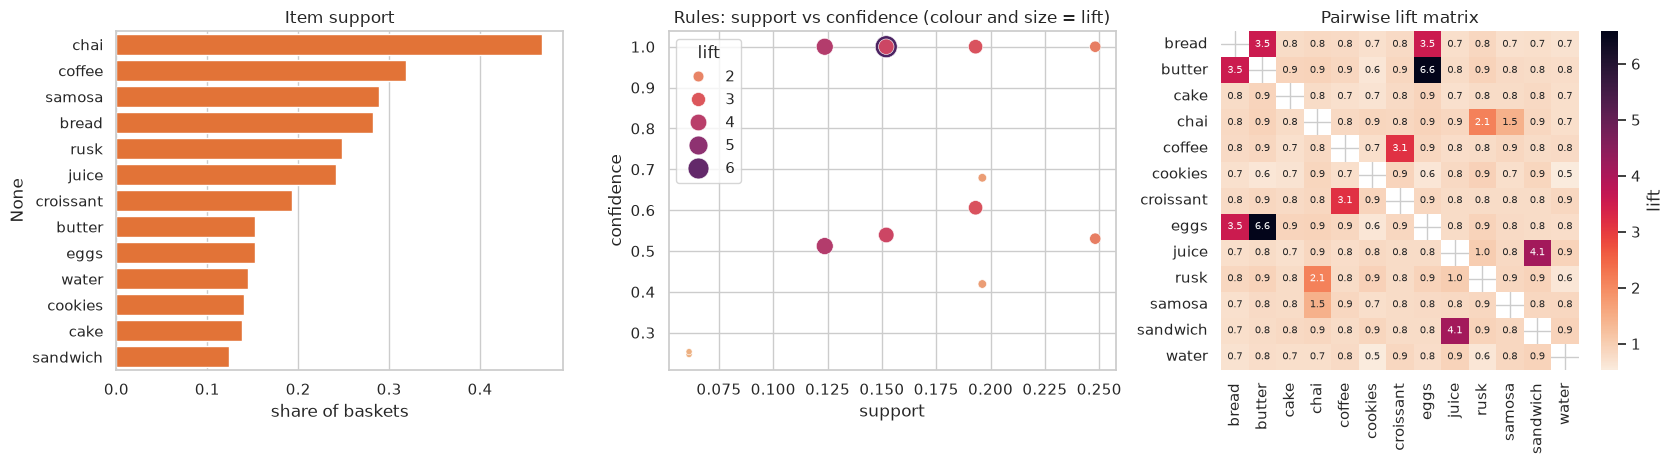

In [4]:
"""Full rule table (support, confidence, lift, leverage, conviction) and three Seaborn charts."""
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

rng = np.random.default_rng(3)
# A bakery-cafe: some items are bought together on purpose
combos = [(["chai", "rusk"], .22), (["coffee", "croissant"], .15), (["bread", "butter", "eggs"], .12),
          (["chai", "samosa"], .14), (["juice", "sandwich"], .10)]
singles = ["chai", "coffee", "bread", "cake", "juice", "cookies", "samosa", "water"]
baskets = []
for _ in range(3000):
    b = set()
    for combo, p in combos:
        if rng.random() < p:
            b.update(combo)
    b.update(rng.choice(singles, rng.integers(0, 3), replace=False))
    if b:
        baskets.append(sorted(str(x) for x in b))          # plain str (not numpy str) for mlxtend
te = TransactionEncoder(); onehot = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
print("transactions:", len(onehot), "| items:", onehot.shape[1])

freq = fpgrowth(onehot, min_support=0.03, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1.0)
# keep simple one-item -> one-item rules: long rules that glue two unrelated patterns together get inflated lifts
rules = rules[(rules.antecedents.apply(len) == 1) & (rules.consequents.apply(len) == 1)].copy()
rules["rule"] = rules.antecedents.apply(lambda s: "+".join(sorted(s))) + " -> " + rules.consequents.apply(lambda s: "+".join(sorted(s)))
top = rules.sort_values("lift", ascending=False).head(8)
print(top[["rule", "support", "confidence", "lift", "leverage", "conviction"]].round(3).to_string(index=False))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
item_sup = onehot.mean().sort_values(ascending=False)
sns.barplot(x=item_sup.values, y=item_sup.index, ax=ax[0], color="#FF6B1A"); ax[0].set_title("Item support"); ax[0].set_xlabel("share of baskets")
sns.scatterplot(data=rules, x="support", y="confidence", hue="lift", size="lift", palette="flare", sizes=(20, 250), ax=ax[1])
ax[1].set_title("Rules: support vs confidence (colour and size = lift)")
co = onehot.T.astype(int) @ onehot.astype(int)
lift_m = (co / len(onehot)) / np.outer(item_sup.reindex(co.index), item_sup.reindex(co.columns))
lift_m = lift_m.mask(np.eye(len(lift_m), dtype=bool))       # hide the diagonal (item with itself)
sns.heatmap(lift_m, cmap="rocket_r", annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax[2], cbar_kws={"label": "lift"})
ax[2].set_title("Pairwise lift matrix")
fig.tight_layout(); fig.savefig("session-09_rules_seaborn.png", dpi=100); plt.show()

### Example 5 · Advanced: more Seaborn for exploring patterns over time and groups

busiest weekday-hour: Sat 19:00 with 85 transactions
           mean    50%     max
customer                      
member    732.0  639.0  3457.0
walk-in   619.0  541.0  3017.0


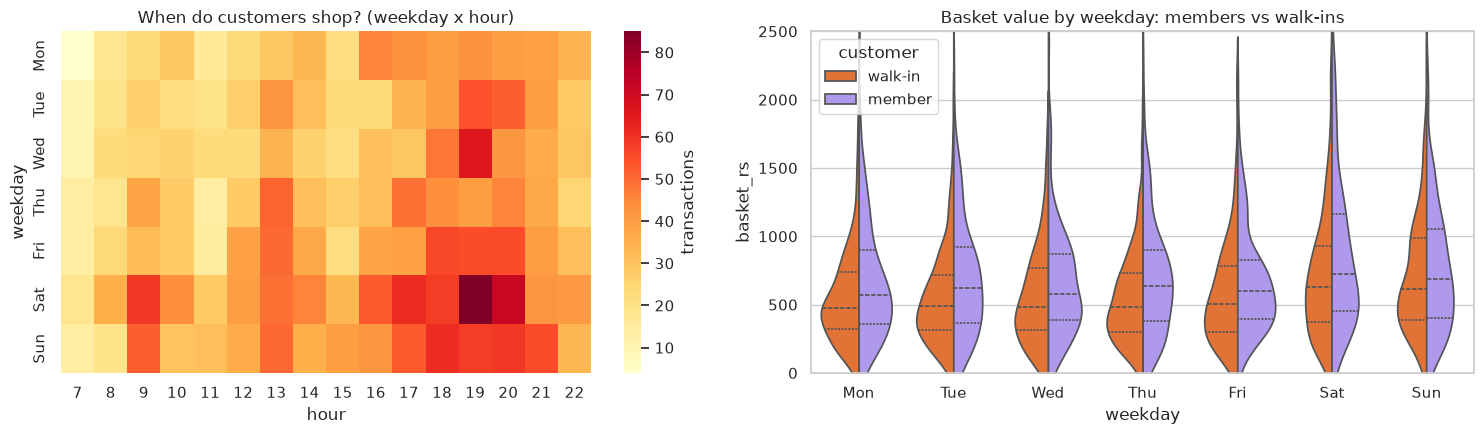

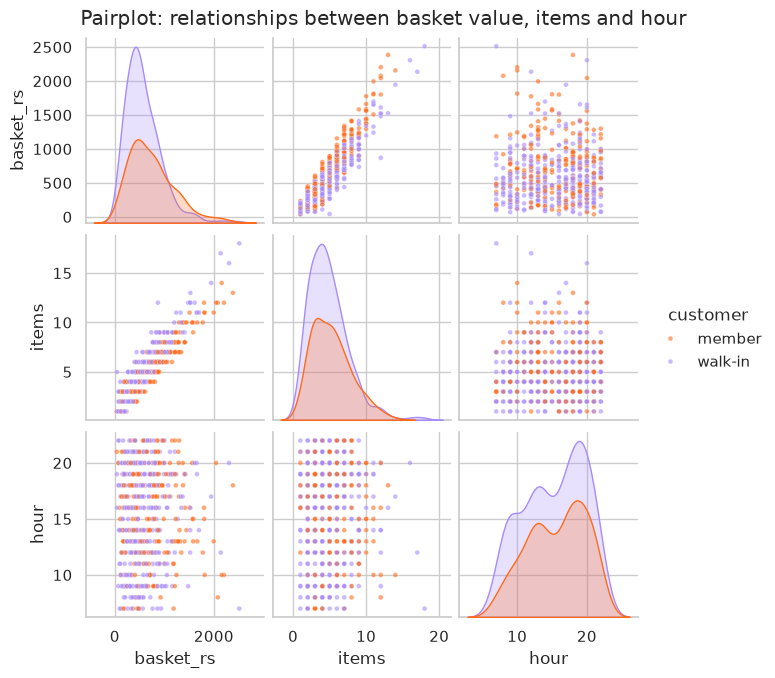

In [5]:
"""Seaborn patterns: hourly x weekday heatmap, violin plots by group, and a pairplot."""
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rng = np.random.default_rng(4)
n = 4000
df = pd.DataFrame({"hour": rng.choice(range(7, 23), n, p=np.r_[[2, 4, 6, 5, 4, 6, 8, 6, 5, 6, 8, 9, 10, 9, 7, 5]] / 100),
                   "weekday": rng.choice(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], n, p=[.12, .12, .12, .13, .15, .19, .17])})
df["basket_rs"] = (rng.gamma(2.5, 220, n) * np.where(df.weekday.isin(["Sat", "Sun"]), 1.3, 1)).round()
df["items"] = (df.basket_rs / 150 + rng.poisson(1, n)).round().clip(1)
df["customer"] = np.where(rng.random(n) < .4, "member", "walk-in")
df.loc[df.customer == "member", "basket_rs"] *= 1.2

order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = df.pivot_table(index="weekday", columns="hour", values="basket_rs", aggfunc="size").reindex(order)
day, hour = grid.stack().idxmax()
print(f"busiest weekday-hour: {day} {int(hour)}:00 with {int(grid.values.max())} transactions")
print(df.groupby("customer")["basket_rs"].describe()[["mean", "50%", "max"]].round(0))

sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(15, 4.5))
ax1 = fig.add_subplot(1, 2, 1)
sns.heatmap(grid, cmap="YlOrRd", ax=ax1, cbar_kws={"label": "transactions"}); ax1.set_title("When do customers shop? (weekday x hour)")
ax2 = fig.add_subplot(1, 2, 2)
sns.violinplot(data=df, x="weekday", y="basket_rs", hue="customer", split=True, order=order, inner="quart", ax=ax2,
               palette=["#FF6B1A", "#A78BFA"])
ax2.set_ylim(0, 2500); ax2.set_title("Basket value by weekday: members vs walk-ins")
fig.tight_layout(); fig.savefig("session-09_seaborn_patterns.png", dpi=100); plt.show()

g = sns.pairplot(df.sample(600, random_state=0)[["basket_rs", "items", "hour", "customer"]], hue="customer",
                 palette=["#FF6B1A", "#A78BFA"], plot_kws={"s": 12, "alpha": .6}, height=2.2)
g.figure.suptitle("Pairplot: relationships between basket value, items and hour", y=1.02)
g.savefig("session-09_pairplot.png", dpi=90); plt.show()

### 🏙️ Real-life data problem: a supermarket's market basket analysis

raw invoice lines: 30829 | cancelled lines: 308
basket matrix: (7988, 20)

frequent itemsets: 285 | rules after filters: 216 | after removing duplicates: 107
                            rule  support  confidence  lift
 cooking oil + rice  ->  lentils    0.065       0.774 4.325
          eggs + milk  ->  bread    0.123       0.829 3.382
    eggs + rice  ->  cooking oil    0.023       0.536 2.943
    rice + tomatoes  ->  lentils    0.024       0.519 2.902
    rusk + soft drink  ->  chips    0.021       0.556 2.876
chips + tomatoes  ->  soft drink    0.026       0.542 2.850
  chips + onions  ->  soft drink    0.026       0.542 2.848
 cooking oil + eggs  ->  lentils    0.022       0.507 2.835
        eggs + rice  ->  lentils    0.021       0.506 2.828
    eggs + soft drink  ->  chips    0.024       0.545 2.821

high-confidence but NOT useful (lift ~ 1, consequent is just popular):
                      rule  confidence  lift
            shampoo -> tea        0.32  1.03
       lentils+rice 

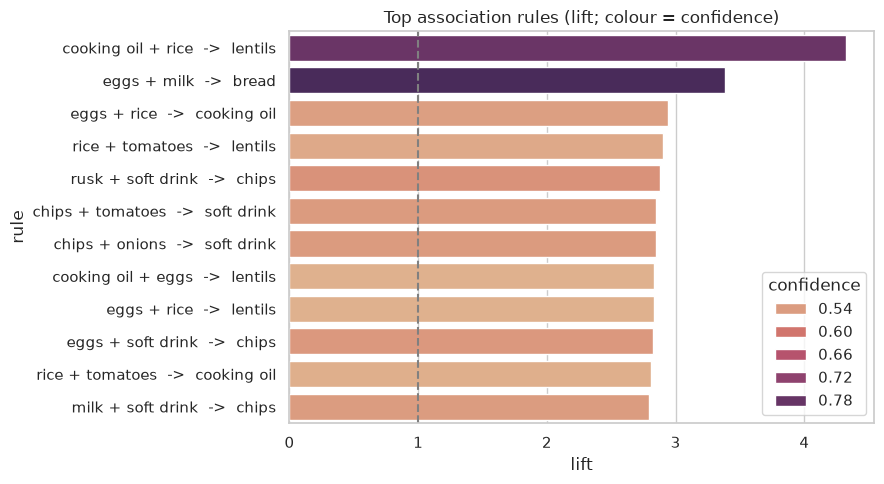

In [6]:
"""Real-life problem: end-to-end market basket analysis from raw invoice lines to recommended actions."""
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import fpgrowth, association_rules

rng = np.random.default_rng(7)
catalogue = ["milk", "bread", "eggs", "butter", "tea", "sugar", "rusk", "rice", "lentils", "cooking oil",
             "onions", "tomatoes", "yogurt", "biscuits", "soft drink", "chips", "nappies", "baby wipes", "shampoo", "soap"]
patterns = [(["milk", "bread", "eggs"], .20), (["tea", "sugar"], .18), (["tea", "rusk"], .12), (["rice", "lentils", "cooking oil"], .10),
            (["onions", "tomatoes"], .22), (["soft drink", "chips"], .12), (["nappies", "baby wipes"], .05), (["shampoo", "soap"], .06)]
lines = []
for inv in range(8000):
    items = set()
    for combo, p in patterns:
        if rng.random() < p:
            items.update(c for c in combo if rng.random() < .85)       # not always the full combo
    items.update(rng.choice(catalogue, rng.integers(1, 4), replace=False))
    for it in items:
        lines.append((f"INV{inv:05d}", str(it), int(rng.integers(1, 4))))
raw = pd.DataFrame(lines, columns=["invoice", "item", "qty"])
cancel = raw.sample(frac=.01, random_state=1).index
raw.loc[cancel, "qty"] = -raw.loc[cancel, "qty"]                       # returns / cancellations
print("raw invoice lines:", len(raw), "| cancelled lines:", (raw.qty < 0).sum())

# 1. Clean: drop cancelled lines, build a one-hot basket matrix
clean = raw[raw.qty > 0]
basket = clean.assign(v=True).pivot_table(index="invoice", columns="item", values="v", aggfunc="any", fill_value=False)
print("basket matrix:", basket.shape)

# 2. Mine and 3. filter rules
freq = fpgrowth(basket, min_support=0.02, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1.3)
rules = rules[(rules.confidence >= .3) & (rules.consequents.apply(len) == 1) & (rules.antecedents.apply(len) <= 2)].copy()
# (single-item consequents, at most two antecedents: longer rules mostly glue two unrelated patterns together)
rules["rule"] = rules.antecedents.apply(lambda s: " + ".join(sorted(s))) + "  ->  " + rules.consequents.apply(lambda s: " + ".join(sorted(s)))
# 4. Remove redundancy: keep the single best rule per unordered item set
rules["itemset"] = rules.apply(lambda r: frozenset(r.antecedents | r.consequents), axis=1)
best = rules.sort_values("lift", ascending=False).drop_duplicates("itemset")
print(f"\nfrequent itemsets: {len(freq)} | rules after filters: {len(rules)} | after removing duplicates: {len(best)}")
print(best[["rule", "support", "confidence", "lift"]].head(10).round(3).to_string(index=False))

weak = association_rules(freq, metric="lift", min_threshold=0).query("confidence > 0.3 and lift < 1.1")
weak = weak.assign(rule=weak.antecedents.apply(lambda s: "+".join(sorted(s))) + " -> " + weak.consequents.apply(lambda s: "+".join(sorted(s))))
print("\nhigh-confidence but NOT useful (lift ~ 1, consequent is just popular):")
print(weak.sort_values("confidence", ascending=False)[["rule", "confidence", "lift"]].head(4).round(2).to_string(index=False))

top = best.head(12)
plt.figure(figsize=(9, 5))
sns.barplot(data=top, y="rule", x="lift", hue="confidence", palette="flare", dodge=False)
plt.axvline(1, color="grey", ls="--"); plt.title("Top association rules (lift; colour = confidence)")
plt.tight_layout(); plt.savefig("session-09_mba_rules.png", dpi=110); plt.show()

### 🧩 Mini project: "frequently bought together" recommender

In [7]:
"""Mini project: turn association rules into a 'frequently bought together' recommender with a fallback."""
import numpy as np
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

rng = np.random.default_rng(11)
families = {"stationery": ["notebook", "pen", "pencil", "eraser", "ruler"], "tech": ["laptop", "mouse", "laptop bag", "usb drive"],
            "phone": ["phone", "phone case", "charger", "screen guard"], "printing": ["printer ink", "a4 paper"]}
baskets = []
for _ in range(5000):
    fam = rng.choice(list(families), p=[.45, .2, .25, .1])
    items = list(rng.choice(families[fam], rng.integers(1, len(families[fam]) + 1), replace=False))
    if rng.random() < .15:
        items.append(rng.choice(sum(families.values(), [])))
    baskets.append(sorted({str(x) for x in items}))
te = TransactionEncoder(); onehot = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
rules = association_rules(fpgrowth(onehot, min_support=0.01, use_colnames=True), metric="lift", min_threshold=1.2)
popular = onehot.mean().sort_values(ascending=False)

def recommend(cart, k=3):
    """Score candidate items by the best lift x confidence of rules whose antecedent is inside the cart."""
    cart = set(cart)
    ok = rules[rules.antecedents.apply(lambda a: a <= cart)]
    scores = {}
    for _, r in ok.iterrows():
        for item in r.consequents - cart:
            scores[item] = max(scores.get(item, 0), r.lift * r.confidence)
    recs = [i for i, _ in sorted(scores.items(), key=lambda x: -x[1])][:k]
    for item in popular.index:                       # fallback: most popular items not in the cart
        if len(recs) >= k: break
        if item not in cart and item not in recs:
            recs.append(item)
    return recs

for cart in [["laptop"], ["phone", "charger"], ["notebook"], ["printer ink"], ["a4 paper", "pen"]]:
    print(f"cart {cart} -> recommend {recommend(cart)}")
print(f"\nrules available: {len(rules)}")

cart ['laptop'] -> recommend ['mouse', 'laptop bag', 'usb drive']
cart ['phone', 'charger'] -> recommend ['screen guard', 'phone case', 'pen']
cart ['notebook'] -> recommend ['eraser', 'ruler', 'pen']
cart ['printer ink'] -> recommend ['a4 paper', 'pen', 'notebook']
cart ['a4 paper', 'pen'] -> recommend ['printer ink', 'eraser', 'notebook']

rules available: 282
